# Chain of thought: why letting a model write its steps makes it smarter
### Lecture 2 of *Reasoning LLMs from Scratch*, for readers new to deep learning

**TL;DR.** A language model answers by running its input through a fixed stack of layers once per output token. That fixed stack can only do a fixed amount of *serial* thinking, so a problem that needs many dependent steps (add up 12 numbers, track a running total) can be out of reach if the model must answer in a single token. **Chain of thought** (CoT) lets the model write the intermediate steps before the answer, and every written step is a new pass through the stack. In our toy experiment, a 2-layer transformer trained on the *parity of n bits* (is the number of 1s even or odd?) answers 100% of questions at n = 4 either way, but at n = 8 it falls to **chance level (about 50%) when asked for the answer directly, while the same model trained to write the running parity first reaches 100%** (same size, same training budget, same data). The price is paid in output length and in a new failure mode: one wrong step ruins the answer.

We keep every claim tied to a run you can repeat in this notebook, on a Mac CPU, in a few minutes. We say plainly where we did **not** measure something, notably real pretrained language models (Section 6).

| section | what we do | key number |
|---|---|---|
| 1 | What a model computes per token | a fixed number of layers = a fixed amount of serial work |
| 2 | A problem a single pass cannot learn | direct answer: 100% at n = 4, chance at n = 8 |
| 3 | Writing the steps first | the same model reaches 100% with steps |
| 4 | Why it works | serial steps per answer: L → L × (tokens written) |
| 5 | What it costs | more tokens, and a wrong step carries through |
| 6 | Prompting versus training for CoT | not measured here (stated) |
| 7 | Side by side | table |

*Prerequisite:* none beyond knowing that a neural network is trained by gradient descent. We explain tokens, next-token prediction and the transformer as they come up.

In [1]:
import io, math, time, warnings
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, display
warnings.filterwarnings("ignore")
torch.set_num_threads(4); torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
ASSETS = Path("../../assets/reasoning").resolve(); ASSETS.mkdir(parents=True, exist_ok=True)
DIRECT_C, COT_C = "#c92a2a", "#2f9e44"
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail)); print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")
def fig_png(fig, dpi=80):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi); plt.close(fig); return buf.getvalue()
def save_gif(frames, path, ms=450, hold_last=1500):
    imgs = [PILImage.open(io.BytesIO(b)).convert("RGB").convert("P", palette=PILImage.ADAPTIVE, colors=128) for b in frames]
    dur = [ms] * len(imgs); dur[-1] = hold_last
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=dur, loop=0, optimize=True, disposal=2); return path
print("torch", torch.__version__)

torch 2.15.0


## 1. What a model computes per token

**A tiny example.** Try to answer this in your head, in one breath, without writing anything: *what is 47 × 36?* Most people cannot. Now take a pencil: 47 × 6 = 282, 47 × 30 = 1,410, 282 + 1,410 = **1,692**. You did not become smarter when you picked up the pencil. You changed *how much work you are allowed to do before the answer must come out*: the paper let you do three small steps in sequence instead of one impossible big one.

**General definition.** A language model works on *tokens*, small pieces of text (a word, part of a word, a digit). It does one thing: given the tokens so far, output a probability for the next token (*next-token prediction*). To produce each token it runs the input once through a stack of L layers (a *transformer*, Vaswani et al., 2017), a *forward pass*. Inside one pass the layers run **one after another**, so a stack with L layers has at most about L stages of dependent computation; within a layer many things happen in parallel, but a result from layer 3 cannot be used until layer 3 is finished. We call this the **serial depth** of one pass.

**How it is implemented.** The model we build below is a real (tiny) transformer in PyTorch: an embedding table that turns tokens into vectors, 2 layers that mix information between positions (*attention*) and process each position (*feed-forward network*), and a final layer that scores the next token. A token is generated by one pass; the generated token is appended to the input; the next token needs another pass. This loop, *autoregressive generation*, is the mechanism Section 4 relies on.

In [2]:
SEP = 2                                                          # tokens: 0 = bit 0, 1 = bit 1, 2 = separator
class TinyLM(nn.Module):
    """A small causal transformer: L layers, width d. Reads tokens left to right, predicts the next token."""
    def __init__(s, L=2, d=64, heads=4, T=64):
        super().__init__(); s.L = L
        s.emb, s.pos = nn.Embedding(3, d), nn.Embedding(T, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.0, batch_first=True, norm_first=True)
        s.enc = nn.TransformerEncoder(layer, L); s.ln = nn.LayerNorm(d); s.out = nn.Linear(d, 3)
    def forward(s, x):
        T = x.shape[1]; causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)       # position t may not look at t+1...
        h = s.emb(x) + s.pos(torch.arange(T)); return s.out(s.ln(s.enc(h, mask=causal, is_causal=True)))
m0 = TinyLM()
print(f"layers L = {m0.L}  | parameters = {sum(p.numel() for p in m0.parameters()):,}")
print("logits for a 6-token input:", tuple(m0(torch.randint(0, 2, (1, 6))).shape), "-> one score per token type at every position")
check("the model has exactly 2 layers = serial depth 2 per pass", m0.L == 2 and len(m0.enc.layers) == 2)

layers L = 2  | parameters = 104,579
logits for a 6-token input: (1, 6, 3) -> one score per token type at every position
PASS - the model has exactly 2 layers = serial depth 2 per pass 


The stack has **2 layers**: any single token it emits is the result of at most about two stages of dependent computation (the exact count of "stages" inside a layer is a detail we do not need). Real models have 30 to 100+ layers, so their per-token serial depth is larger, but still a fixed number that does not grow with the problem. That is the constraint chain of thought gets around. To see it bite, we need a problem whose difficulty we can dial up.

## 2. A problem a single pass cannot learn

**A tiny example.** *Parity*: given bits `1 0 1 1`, is the number of 1s even (answer 0) or odd (answer 1)? Count: three 1s, odd, so the answer is **1**. With `1 0 1 1 0 1 1 0` (n = 8) there are five 1s, answer **1** again. The rule is the same at every size, but the work grows: to be sure of the answer you have to look at *every* bit, and flipping any single bit flips the answer. That last property is what makes parity a standard stress test.

**General definition and setup.** We train one model on one task: read n random bits, then a separator token, then output the parity. We call this the **direct** setting (the answer is the very next token after the separator). Everything about the model is fixed across experiments: 2 layers, width 64, 4 attention heads, about 100,000 parameters, AdamW with learning rate 2e-3, batch size 256, **1,500 training steps**. Only n changes. We measure *accuracy on 1,000 fresh random questions* (chance = 50%).

**A caution about what we are claiming.** In theory, whether a fixed-depth transformer *can* compute parity of long inputs depends on assumptions about width and number precision, and there are both positive and negative results. What we measure is narrower and practical: **with this model size and this training budget, does gradient descent find a solution?** We will also check whether simply training longer rescues the direct model.

In [3]:
def make_batch(n, B, cot, g):
    bits = torch.randint(0, 2, (B, n), generator=g); run = bits.cumsum(1) % 2                 # run[:, k] = parity of the first k+1 bits
    tgt = run if cot else run[:, -1:]
    return torch.cat([bits, torch.full((B, 1), SEP), tgt], 1), tgt

def train(n, cot, steps, seed=0, B=256, lr=2e-3):
    g = torch.Generator().manual_seed(seed); torch.manual_seed(seed); m = TinyLM(); opt = torch.optim.AdamW(m.parameters(), lr=lr)
    for _ in range(steps):
        x, t = make_batch(n, B, cot, g); k = t.shape[1]
        loss = F.cross_entropy(m(x[:, :-1])[:, -k:].reshape(-1, 3), t.reshape(-1))                # loss only on the answer / steps
        opt.zero_grad(); loss.backward(); opt.step()
    return m

@torch.no_grad()
def generate(m, prefix, k):
    cur = prefix
    for _ in range(k): cur = torch.cat([cur, m(cur)[:, -1].argmax(-1, keepdim=True)], 1)         # one forward pass per new token
    return cur

@torch.no_grad()
def accuracy(m, n, cot, B=1000, seed=123):
    g = torch.Generator().manual_seed(seed); x, t = make_batch(n, B, cot, g); k = t.shape[1]
    out = generate(m, x[:, :n + 1], k); return (out[:, -1] == t[:, -1]).float().mean().item()    # final answer correct?

NS, SEEDS, STEPS = (2, 4, 6, 8, 12), (0, 1), 1500
res = {"direct": {}, "cot": {}}; models = {}
t0 = time.time()
for cot in (False, True):
    for n in NS:
        accs = []
        for sd in SEEDS:
            m = train(n, cot, STEPS, seed=sd); accs.append(accuracy(m, n, cot)); models[(cot, n, sd)] = m
        res["cot" if cot else "direct"][n] = accs
print(f"trained {2*len(NS)*len(SEEDS)} models in {time.time()-t0:.0f} s")
print(f"{'n bits':>7s}{'direct acc (2 seeds)':>26s}{'CoT acc (2 seeds)':>24s}")
for n in NS: print(f"{n:7d}{str([round(a, 3) for a in res['direct'][n]]):>26s}{str([round(a, 3) for a in res['cot'][n]]):>24s}")

trained 20 models in 1188 s
 n bits      direct acc (2 seeds)       CoT acc (2 seeds)
      2                [1.0, 1.0]              [1.0, 1.0]
      4                [1.0, 1.0]              [1.0, 1.0]
      6             [0.952, 0.79]              [1.0, 1.0]
      8            [0.505, 0.495]              [1.0, 1.0]
     12            [0.496, 0.504]              [1.0, 1.0]


Here is the measurement we hoped to avoid being surprised by. Read the *direct* column first.

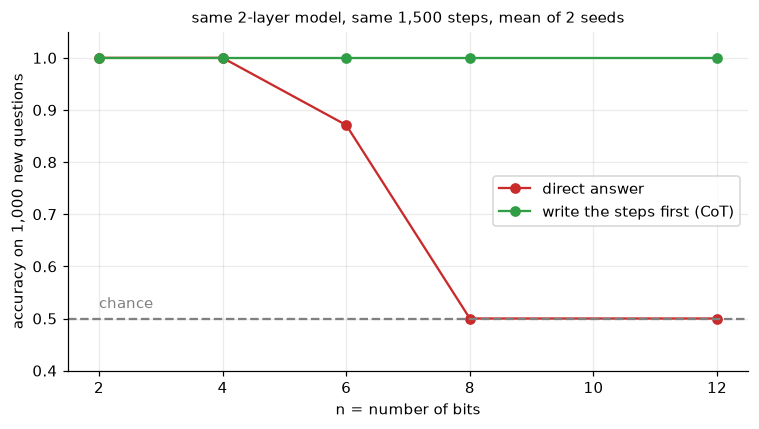

PASS - direct answer is near-perfect at n = 2 and n = 4 
PASS - direct answer is near chance (<0.60) at n = 8 and n = 12 under this budget | {8: [0.5, 0.5], 12: [0.5, 0.5]}


In [4]:
mean = lambda k, n: float(np.mean(res[k][n]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(NS, [mean("direct", n) for n in NS], "-o", color=DIRECT_C, label="direct answer"); ax.plot(NS, [mean("cot", n) for n in NS], "-o", color=COT_C, label="write the steps first (CoT)")
ax.axhline(0.5, color="gray", ls="--"); ax.text(NS[0], 0.52, "chance", color="gray")
ax.set_xlabel("n = number of bits"); ax.set_ylabel("accuracy on 1,000 new questions"); ax.set_ylim(0.4, 1.05); ax.legend(loc="center right")
ax.set_title("same 2-layer model, same 1,500 steps, mean of 2 seeds", fontsize=10); plt.tight_layout(); plt.savefig(ASSETS / "cot_accuracy_vs_n.png", dpi=110); plt.show()
check("direct answer is near-perfect at n = 2 and n = 4", all(a > 0.97 for n in (2, 4) for a in res["direct"][n]))
check("direct answer is near chance (<0.60) at n = 8 and n = 12 under this budget", all(a < 0.60 for n in (8, 12) for a in res["direct"][n]), str({n: [round(a, 2) for a in res['direct'][n]] for n in (8, 12)}))

[FIGURE: accuracy against the number of bits. **Notice** the red direct-answer line is flat at the top for n ≤ 4 and then falls onto the grey chance line; it drops steeply between n = 4 and n = 8 (0.87 at n = 6, with the two seeds at 0.95 and 0.79) and is at chance from n = 8.]

This is the **failed baseline**, stated plainly. **What we tried:** train the 2-layer model to output the parity of n bits as the next token. **Symptom:** perfect at n ≤ 4, and at n = 8 and n = 12 the accuracy sits at chance (about 50%, see the printed values) after 1,500 steps, at exactly 0.50 on both seeds, so the model has learned nothing better than guessing (we did not log the training loss, so this is inferred from accuracy). **Root cause:** parity has no partial credit. A model that has looked at 7 of 8 bits and knows nothing about the 8th is exactly at 50%, so there is no gradient signal that says "you are getting warmer", and the model must discover the full all-bits interaction in one jump. **What we do about it:** first, check that this is not just a matter of training time.

In [5]:
n_long = 8
m_long = train(n_long, False, 6000, seed=0)                       # 4x more training for the direct model
acc_long = accuracy(m_long, n_long, False)
print(f"n = 8, direct answer: 1,500 steps -> {mean('direct', 8):.3f}   |   6,000 steps (4x longer) -> {acc_long:.3f}")
check("4x longer training does not rescue the direct model at n = 8 (<0.60)", acc_long < 0.60, f"{acc_long:.3f}")

n = 8, direct answer: 1,500 steps -> 0.500   |   6,000 steps (4x longer) -> 0.505
PASS - 4x longer training does not rescue the direct model at n = 8 (<0.60) | 0.505


Four times more training does not help in our setting (see the printed accuracy). We do **not** claim the direct model could never learn n = 8: with a bigger model, much more training or a different optimiser, gradient descent may find the solution, and we only tested this one configuration. What we can say is that **under an identical, fixed budget, the direct format fails where the step-by-step format succeeds**, which is the comparison the next section makes.

## 3. Writing the steps first

**A tiny example.** Instead of asking for the parity of `1 0 1 1 0 1 1 0` at once, ask the model to write the *running* parity after each bit, like a person ticking a tally:

| bit read | `1` | `0` | `1` | `1` | `0` | `1` | `1` | `0` |
|---|---|---|---|---|---|---|---|---|
| running parity written | **1** | **1** | **0** | **1** | **1** | **0** | **1** | **1** |

The last number is the answer (1). Each written number depends only on **two things**: the bit just read and the previous written number (new parity = previous parity XOR the bit). That is as easy as learning gets: a two-input lookup table, and every step has a correct label, so training gives the model feedback after every bit instead of only at the end.

**General definition.** *Chain of thought* means the output contains intermediate reasoning tokens before the final answer. The idea of a model writing a *scratchpad* was shown for programs and arithmetic by Nye et al., 2021, and for natural-language reasoning in large models by Wei et al., 2022. **How it is implemented here:** nothing about the model changes. Only the *target* changes, from the single token `answer` to the sequence of n running parities, and the model reads its own earlier outputs as input, as in Section 1. The comparison in the cell above already contains this: the green line is the same model, same budget, with step-by-step targets.

In [6]:
print(f"{'n bits':>7s}{'direct (mean)':>15s}{'CoT (mean)':>13s}{'gain':>8s}")
for n in NS: print(f"{n:7d}{mean('direct', n):15.3f}{mean('cot', n):13.3f}{mean('cot', n) - mean('direct', n):+8.3f}")
check("CoT reaches >=0.99 accuracy at every tested n (including 12)", all(a >= 0.99 for n in NS for a in res["cot"][n]), str({n: [round(a, 3) for a in res['cot'][n]] for n in NS}))
check("at n = 8, CoT beats direct by more than 0.40 with the same model and budget", mean("cot", 8) - mean("direct", 8) > 0.40)
# show the model's real output on one example
ex_bits = torch.tensor([[1, 0, 1, 1, 0, 1, 1, 0]]); m8 = models[(True, 8, 0)]
out = generate(m8, torch.cat([ex_bits, torch.tensor([[SEP]])], 1), 8)[0, 9:]
print("\nbits               :", ex_bits[0].tolist()); print("model wrote        :", out.tolist()); print("true running parity:", (ex_bits.cumsum(1) % 2)[0].tolist())
check("on the worked example the model writes the true running parities", out.tolist() == (ex_bits.cumsum(1) % 2)[0].tolist())

 n bits  direct (mean)   CoT (mean)    gain
      2          1.000        1.000  +0.000
      4          1.000        1.000  +0.000
      6          0.871        1.000  +0.129
      8          0.500        1.000  +0.500
     12          0.500        1.000  +0.500
PASS - CoT reaches >=0.99 accuracy at every tested n (including 12) | {2: [1.0, 1.0], 4: [1.0, 1.0], 6: [1.0, 1.0], 8: [1.0, 1.0], 12: [1.0, 1.0]}
PASS - at n = 8, CoT beats direct by more than 0.40 with the same model and budget 

bits               : [1, 0, 1, 1, 0, 1, 1, 0]
model wrote        : [1, 1, 0, 1, 1, 0, 1, 1]
true running parity: [1, 1, 0, 1, 1, 0, 1, 1]
PASS - on the worked example the model writes the true running parities 


In our setting, writing the steps takes the model from **chance (about 50%) to at least 99% at n = 8 and n = 12** on the same 2-layer network, for the same 1,500 steps, and its output on the worked example is exactly the running-parity row from the table above. The benefit has a cost that we deliberately put off until Section 5: the model now writes 8 or 12 tokens instead of 1. Before counting that cost, we want to understand *why* the steps help, because "it is easier to learn" is only part of the story.

## 4. Why it works

**A tiny example.** Count how many *dependent* stages of computation separate the first bit from the answer. In the direct setting, the model has 2 layers, so **2 stages** in total, no matter if n = 4 or n = 400. In the CoT setting with n = 8, the model writes 8 tokens; token 2 can read token 1, token 3 can read token 2, and so on, so the first bit's influence passes through **8 passes × 2 layers = 16 stages** before the final answer token. Writing a token *puts an intermediate result into the input of the next pass*, so the length of the chain becomes extra depth.

**General definition.** For L layers and k generated tokens that each depend on the previous one, the serial depth available is about **L × k**, instead of **L** (for a single-token answer). Intuitively, the generated text acts as the model's working memory (*scratchpad*), and each step only has to do *a small piece of the work*. Theory papers make this precise under assumptions we do not reproduce here: for example, Feng et al., 2023 and Merrill & Sabharwal, 2023 show that allowing a number of CoT steps that grows with the input lets transformers solve problems that bounded-depth ones are believed to find hard. We cite them for context and rely on our own measurement for the claim.

**How it is implemented.** In code, the loop below is all there is: the output of pass *t* is appended to the input of pass *t + 1*. The cell draws the loop as it actually ran, using the real model's output for the 8-bit example.

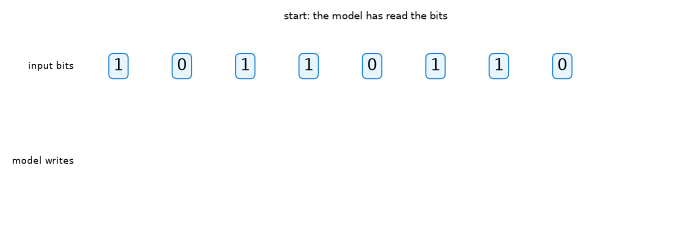

In [7]:
def draw_step(k, bits, outs, title):
    n = len(bits); fig, ax = plt.subplots(figsize=(9, 3.2)); ax.set_xlim(-0.8, n + 0.6); ax.set_ylim(-0.4, 2.6); ax.axis("off")
    ax.text(-0.7, 2.0, "input bits", ha="right", va="center", fontsize=9); ax.text(-0.7, 0.6, "model writes", ha="right", va="center", fontsize=9)
    for i, b in enumerate(bits): ax.text(i, 2.0, str(b), ha="center", va="center", fontsize=15, bbox=dict(boxstyle="round", fc="#e7f5ff" if i != k - 1 else "#ffd43b", ec="#1c7ed6"))
    for i in range(k): ax.text(i, 0.6, str(outs[i]), ha="center", va="center", fontsize=15, color="white", bbox=dict(boxstyle="round", fc=COT_C if i != k - 1 else "#e8590c", ec="none"))
    if k >= 1:
        ax.annotate("", xy=(k - 1, 0.95), xytext=(k - 1, 1.65), arrowprops=dict(arrowstyle="->", color="#e8590c", lw=2))
        if k >= 2: ax.annotate("", xy=(k - 1.1, 0.6), xytext=(k - 1.9, 0.6), arrowprops=dict(arrowstyle="->", color="#e8590c", lw=2, ls="--"))
    ax.set_title(title, fontsize=10); plt.tight_layout(); return fig
bits8 = ex_bits[0].tolist(); outs8 = out.tolist(); frames = []
for k in range(0, 9):
    for _ in range(1 if k else 2):
        t = "start: the model has read the bits" if k == 0 else f"pass {k}: reads bit {k} (yellow) and its own previous token -> writes {outs8[k-1]}"
        frames.append(fig_png(draw_step(k, bits8, outs8, t), 75))
gif = save_gif(frames, ASSETS / "cot_unrolled_generation.gif"); display(Image(filename=str(gif)))

[FIGURE: the model writing its steps, one pass per token. **Notice** that each new green box depends on the yellow input bit *and* the box to its left (orange arrows): the left box is the model's own earlier output, fed back in. That feedback arrow is where the extra depth comes from.]

A deliberately small experiment can test whether the extra depth is the real reason, as opposed to "more supervision": give the direct model the same *amount* of training signal but no intermediate result to read. We do not have that control in this notebook, and we want to flag it. What we measured is that the step-by-step format works under the budget where the direct one fails; the *explanation* (serial depth) is consistent with theory and with the diagram, but we did not isolate it from the denser supervision that step targets also provide. The cost side of the ledger is next.

## 5. What it costs

Two costs, each with a number. **First, length.** The direct answer is 1 token; the CoT answer is n tokens plus the answer, and every extra token needs a forward pass. Generating n = 12 steps costs roughly 12 forward passes instead of 1 (the exact wall-clock below is measured on our CPU with no caching tricks, so it exaggerates the ratio a bit compared to an optimised server).

**Second, fragility.** In the direct setting there is one chance to be wrong. In a chain, a *single wrong step* is carried forward, because every later step trusts the earlier ones. If each step is right with probability *p*, a chain of n independent steps is fully right with probability about **p^n**: at p = 0.99 and n = 12 that is 0.99^12 = 0.886, and at p = 0.95 it is 0.54. We test this with models we train **too little on purpose**, so they make real mistakes.

In [8]:
n = 12
@torch.no_grad()
def per_step_accuracy(m, n, B=1000, seed=7):
    g = torch.Generator().manual_seed(seed); x, t = make_batch(n, B, True, g)
    pred = m(x[:, :-1])[:, -n:].argmax(-1)                          # teacher forcing: every step sees the TRUE previous steps
    return (pred == t).float().mean().item()
print(f"{'train steps':>12s}{'per-step acc p':>16s}{'predicted p^n':>15s}{'measured final acc':>20s}")
rows = []
for steps in (60, 100, 150, 250):
    ps, fs = [], []
    for sd in (0, 1):
        mm = train(n, True, steps, seed=sd); ps.append(per_step_accuracy(mm, n)); fs.append(accuracy(mm, n, True))
    p, f = float(np.mean(ps)), float(np.mean(fs)); rows.append((steps, p, p ** n, f)); print(f"{steps:12d}{p:16.3f}{p**n:15.3f}{f:20.3f}")
check("final-answer accuracy of under-trained CoT is below its per-step accuracy (errors compound)", all(f < p for _, p, _, f in rows if p < 0.999))
check("p^n tracks the measured final accuracy within 0.25 (a rough guide, not a law)", all(abs(pn - f) < 0.25 for _, _, pn, f in rows), str([(round(pn, 2), round(f, 2)) for _, _, pn, f in rows]))

 train steps  per-step acc p  predicted p^n  measured final acc


          60           0.950          0.538               0.572


         100           1.000          0.999               0.999


         150           1.000          1.000               1.000


         250           1.000          1.000               1.000
PASS - final-answer accuracy of under-trained CoT is below its per-step accuracy (errors compound) 
PASS - p^n tracks the measured final accuracy within 0.25 (a rough guide, not a law) | [(0.54, 0.57), (1.0, 1.0), (1.0, 1.0), (1.0, 1.0)]


In this experiment the compounding is visible: after 60 training steps the model gets **95.0% of individual steps** right but only **57.2% of whole 12-step answers**, close to the predicted 0.95^12 = 0.538. The effect is short-lived: by 100 steps the chain is already 99.9% right, so only this one row actually tests the compounding claim, and it is one model pair on one task (the other rows are all ≈ 100% and agree trivially). The two numbers are not identical in general because errors are not independent. Now the cleanest way to see fragility: take a fully trained CoT model, let it write its chain, **corrupt one step by hand**, and let it continue.

In [9]:
@torch.no_grad()
def inject_and_continue(m, n, j, B=1000, seed=99):
    g = torch.Generator().manual_seed(seed); x, t = make_batch(n, B, True, g)
    cur = torch.cat([x[:, :n + 1 + j], 1 - t[:, j:j + 1]], 1)        # bits, SEP, j correct steps, then step j deliberately flipped
    wrong_at = j
    cur = generate(m, cur, n - 1 - wrong_at)                        # let the model finish the chain
    return (cur[:, -1] == t[:, -1]).float().mean().item()
m12 = models[(True, 12, 0)]
print("corrupting ONE intermediate step (flipping it) in an otherwise correct chain, n = 12:")
print(f"{'corrupted step':>15s}{'final answer correct':>22s}")
fr = []
for j in (0, 3, 6, 9):
    a = inject_and_continue(m12, 12, j); fr.append(a); print(f"{j+1:15d}{a:22.3f}")
print(f"(clean run, no corruption: {accuracy(m12, 12, True):.3f})")
check("a single corrupted step is NOT repaired: final accuracy drops below 0.10", max(fr) < 0.10, str([round(a, 3) for a in fr]))

corrupting ONE intermediate step (flipping it) in an otherwise correct chain, n = 12:
 corrupted step  final answer correct


              1                 0.000


              4                 0.000


              7                 0.000
             10                 0.000


(clean run, no corruption: 1.000)
PASS - a single corrupted step is NOT repaired: final accuracy drops below 0.10 | [0.0, 0.0, 0.0, 0.0]


**No corrupted chain recovered**: final accuracy was exactly 0.000 for an error injected at step 1, 4, 7 or 10, against 1.000 for the clean chain. The model is behaving exactly as trained: each step is "previous state XOR this bit", so given a wrong previous state it dutifully produces a wrong next one. This is the central trade-off of chain of thought in our setting: **better answers when the steps are right, correlated failure when one is wrong**. Real language models can sometimes notice and repair a bad step, but we did not test that.

We also time the length cost. The numbers are for this CPU and an unoptimised loop, not a serving system.

In [10]:
def time_gen(m, n, cot, reps=20):
    g = torch.Generator().manual_seed(5); x, t = make_batch(n, 64, cot, g); k = t.shape[1]; ts = []
    for _ in range(reps): t0 = time.perf_counter(); generate(m, x[:, :n + 1], k); ts.append(time.perf_counter() - t0)
    return float(np.median(ts[2:])), k
td, kd = time_gen(models[(False, 12, 0)], 12, False); tc, kc = time_gen(models[(True, 12, 0)], 12, True)
print(f"n = 12: direct writes {kd} token  -> {td*1e3:6.1f} ms per batch of 64 | CoT writes {kc} tokens -> {tc*1e3:6.1f} ms ({tc/td:.1f}x)")
check("CoT writes n tokens vs 1 and costs several times more generation time", kc == 12 and kd == 1 and tc / td > 4, f"{tc/td:.1f}x")

n = 12: direct writes 1 token  ->    4.7 ms per batch of 64 | CoT writes 12 tokens ->   72.3 ms (15.3x)
PASS - CoT writes n tokens vs 1 and costs several times more generation time | 15.3x


In our setting the 12-step chain took **72.3 ms against 4.7 ms per batch of 64 (15.3×)** compared with the single-token answer, which is the expected consequence of 12 sequential passes. So, in one sentence, the bargain on this toy is: **12× the tokens and a brittle chain, in exchange for going from a coin flip to a correct answer**. Whether that bargain holds for real language models is a separate question.

## 6. Prompting versus training for CoT

Everything above *trained* the model to write steps. Real language models are usually not trained on parity chains; people instead get them to reason in two other ways.

**Few-shot CoT prompting** (Wei et al., 2022): put a few worked examples with their reasoning in the prompt, then the new question, and a large enough pretrained model imitates the pattern. **Zero-shot CoT** (Kojima et al., 2022): just append a phrase like "Let's think step by step." The function below builds the two prompts so you can see exactly what is sent; no model is called.

In [11]:
FEW_SHOT = """Q: Roger has 5 balls. He buys 2 cans of 3 balls each. How many balls now?
A: He starts with 5. 2 cans of 3 balls is 6 balls. 5 + 6 = 11. The answer is 11.

Q: {question}
A:"""
def few_shot_prompt(q): return FEW_SHOT.format(question=q)
def zero_shot_prompt(q): return f"Q: {q}\nA: Let's think step by step."
q = "A shop sells pens at 4 dollars each. Maya buys 7 pens and pays with a 50 dollar bill. How much change does she get?"
print(few_shot_prompt(q)); print("\n-----\n"); print(zero_shot_prompt(q))
check("both prompt builders contain the question", q in few_shot_prompt(q) and q in zero_shot_prompt(q))

Q: Roger has 5 balls. He buys 2 cans of 3 balls each. How many balls now?
A: He starts with 5. 2 cans of 3 balls is 6 balls. 5 + 6 = 11. The answer is 11.

Q: A shop sells pens at 4 dollars each. Maya buys 7 pens and pays with a 50 dollar bill. How much change does she get?
A:

-----

Q: A shop sells pens at 4 dollars each. Maya buys 7 pens and pays with a 50 dollar bill. How much change does she get?
A: Let's think step by step.
PASS - both prompt builders contain the question 


**What we did not measure.** We did not run a pretrained language model in this notebook, so we make **no measured claim** about how much prompting helps real models, which models it helps, or how it compares to training on reasoning traces. The literature reports that CoT prompting helps mainly for sufficiently large models and multi-step problems (Wei et al., 2022); treat that as a pointer to the papers, not as our result. What *is* ours is the mechanism on a controlled toy: the benefit comes from giving the model room to compute in sequence, and the cost is length and brittleness. The later lectures in this series build on exactly this, by training models to produce *good* chains rather than hoping a prompt elicits them.

## 7. Side by side

| | direct answer | trained chain of thought | prompted chain of thought |
|---|---|---|---|
| what the model writes | the answer only | steps, then the answer | steps, then the answer |
| serial depth per answer | L (fixed) | about L × (number of steps) | about L × (number of steps) |
| our measurement (parity, 2 layers, 1,500 steps) | 100% at n = 4, chance at n = 8 and 12 | ≥ 99% at n = 2 ... 12 | **not measured** |
| output length | 1 token | n tokens (12 at n = 12) | typically many tokens |
| generation cost, n = 12 | 1× | 15.3× (72.3 vs 4.7 ms per batch of 64, CPU) | not measured |
| failure mode | no learning signal (flat loss) | one wrong step propagates (≈0% recovery in our test) | not measured |
| needs special training data | no | yes: step-by-step targets | no, but a large pretrained model |

## Closing thoughts

The idea that intermediate computation should be written out is old in human practice and appears in machine learning as *scratchpads* (Nye et al., 2021), then as chain-of-thought prompting (Wei et al., 2022; Kojima et al., 2022), and now as the training target of reasoning models, which is where this series is heading. What remains open for us: whether the explanation we offered (serial depth) is the whole story, which needs a control we did not run; how these findings change at realistic model sizes and with real text, which we did not test; and how to stop one bad step from ruining a long chain, which later lectures take up when models are trained to check and correct themselves. The next lecture builds on this by looking at how to *train* a model to produce better chains than the ones it would write by default.

In [12]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed"); assert not failed, failed

 #  status  check
 1  PASS    the model has exactly 2 layers = serial depth 2 per pass
 2  PASS    direct answer is near-perfect at n = 2 and n = 4
 3  PASS    direct answer is near chance (<0.60) at n = 8 and n = 12 under this budget
 4  PASS    4x longer training does not rescue the direct model at n = 8 (<0.60)
 5  PASS    CoT reaches >=0.99 accuracy at every tested n (including 12)
 6  PASS    at n = 8, CoT beats direct by more than 0.40 with the same model and budget
 7  PASS    on the worked example the model writes the true running parities
 8  PASS    final-answer accuracy of under-trained CoT is below its per-step accuracy (errors compound)
 9  PASS    p^n tracks the measured final accuracy within 0.25 (a rough guide, not a law)
10  PASS    a single corrupted step is NOT repaired: final accuracy drops below 0.10
11  PASS    CoT writes n tokens vs 1 and costs several times more generation time
12  PASS    both prompt builders contain the question

12 passed, 0 failed


## Exercises
- In Section 2, change the task from parity to the **sum of n digits modulo 10** (tokens 0-9). Does the direct model fail at a larger or smaller n than for parity? Why might that be?
- In Section 2, give the direct model a bigger network (`TinyLM(L=4, d=128)`) and 4,000 steps. Where does the failure move, if at all?
- In Section 3, train the CoT model on n = 8 and test on n = 12. Does it generalise to longer chains? What does that tell you about what it learned?
- In Section 5, corrupt the step *and* ask the model to continue with a sampling temperature above zero. Can randomness ever help it recover?
- Write a second step-by-step format that is *less* helpful (for example, write only every second running parity) and measure how accuracy changes.

## Honest limits
One toy task (parity of n bits), one tiny model (2 layers, about 100,000 parameters), a Mac CPU (about 20 minutes end to end), and 2 seeds per cell with 1,000 test questions each (so accuracies near chance carry roughly ±2 points of noise). **We did not isolate** depth from denser supervision (Section 4), **did not run** any pretrained language model (Section 6), and did not test sampling, longer lengths than n = 12, or other tasks. Theory papers are cited for context only. The step-by-step advantage here is large because parity is close to the worst case for single-pass learning; for tasks where the direct model already works, the benefit can be small or negative once the extra tokens are counted.